# LSTM Classification

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This file implements the LSTM model for document classification.

### Import the required libraries

In [130]:
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score

### Loading the data



In [131]:
# Read the processed dataset
data = pd.read_csv("../synthetic_dataset/document_classified_data.csv")

# Split the string based on space
data["processed_text"] = data["processed_text"].astype("str").apply(lambda x: x.split())

# Load Tokenizers
with open("output/doc_text_tokenizer.pickle", "rb") as file:
    tokenizer = pickle.load(file)

# Load GloVe word embeddings for the docs
with np.load("output/doc_glove_embeddings.npz", allow_pickle=True) as glove_embeddings_data:
    glove_embeddings = glove_embeddings_data["embedding_matrix"]

glove_embeddings.shape

(22262, 300)

In [132]:
# Convert the tokens to sequences
sequences = tokenizer.texts_to_sequences(data["processed_text"])

# Padding the sequences
text_max_len = 100

text_padded_sequences = tf.keras.preprocessing.sequence.pad_sequences(sequences, maxlen=text_max_len, padding="post")

### Model Creation

In [133]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(text_padded_sequences, data["sensitive"], test_size=0.2, random_state=42)

# Build the LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=glove_embeddings.shape[0], output_dim=glove_embeddings.shape[1], weights=[glove_embeddings], input_length=text_max_len, trainable=False),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_16 (Embedding)    (None, 100, 300)          6678600   
                                                                 
 bidirectional_4 (Bidirecti  (None, 128)               186880    
 onal)                                                           
                                                                 
 dense_30 (Dense)            (None, 32)                4128      
                                                                 
 dropout_31 (Dropout)        (None, 32)                0         
                                                                 
 dense_31 (Dense)            (None, 1)                 33        
                                                                 
Total params: 6869641 (26.21 MB)
Trainable params: 191041 (746.25 KB)
Non-trainable params: 6678600 (25.48 MB)
________

### Training and Evaluation



In [134]:
# Adjusting optimizer
model.compile(optimizer="Adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
14/14 [==============================] - 16s 622ms/step - loss: 0.6825 - accuracy: 0.5602 - val_loss: 0.6872 - val_accuracy: 0.5521
Epoch 2/5
14/14 [==============================] - 10s 675ms/step - loss: 0.6517 - accuracy: 0.6157 - val_loss: 0.6562 - val_accuracy: 0.6250
Epoch 3/5
14/14 [==============================] - 9s 637ms/step - loss: 0.6175 - accuracy: 0.6644 - val_loss: 0.6314 - val_accuracy: 0.6875
Epoch 4/5
14/14 [==============================] - 9s 653ms/step - loss: 0.5635 - accuracy: 0.7106 - val_loss: 0.5746 - val_accuracy: 0.7188
Epoch 5/5
14/14 [==============================] - 8s 563ms/step - loss: 0.5108 - accuracy: 0.7396 - val_loss: 0.5662 - val_accuracy: 0.6771


In [135]:
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)

df_scores = pd.DataFrame(columns=["Metric", "Value"])
df_scores = df_scores._append({"Metric": "Accuracy", "Value":accuracy}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Precision", "Value":precision}, ignore_index=True)
df_scores = df_scores._append({"Metric": "Recall", "Value":recall}, ignore_index=True)
df_scores = df_scores._append({"Metric": "F1 score:", "Value":f1}, ignore_index=True)

df_scores.head()

8/8 [==============================] - 1s 68ms/step


,Metric,Value
0,Accuracy,0.670833
1,Precision,0.708955
2,Recall,0.703704
3,F1 score:,0.706320


### Plotting the accuracy

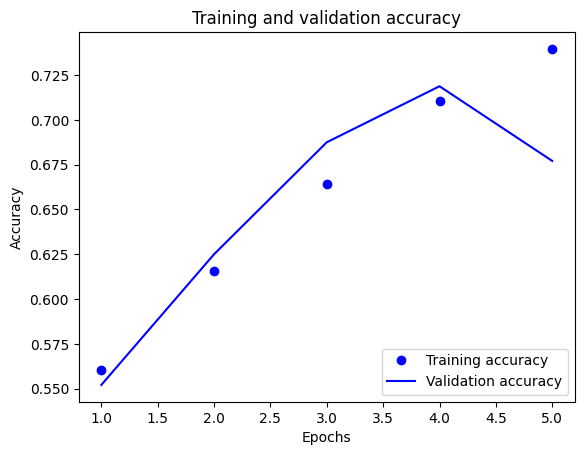

In [136]:
# Plotting the accuracy
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.show()